In [134]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [135]:
path="HousePriceDataset.csv"

In [136]:
df = pd.read_csv(path)

In [137]:
#Replace whitespaces, mutilple hypens etc with one single whitespace.
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

In [138]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29451 entries, 0 to 29450
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   posted_by             29451 non-null  str    
 1   under_construction    29451 non-null  int64  
 2   rera                  29451 non-null  int64  
 3   bhk_no                29451 non-null  int64  
 4   bhk_or_rk             29451 non-null  str    
 5   square_ft             29451 non-null  float64
 6   ready_to_move         29451 non-null  int64  
 7   resale                29451 non-null  int64  
 8   address               29451 non-null  str    
 9   longitude             29451 non-null  float64
 10  latitude              29451 non-null  float64
 11  target_price_in_lacs  29451 non-null  float64
dtypes: float64(4), int64(5), str(3)
memory usage: 2.7 MB


In [139]:
df.head() 

,posted_by,under_construction,rera,bhk_no,bhk_or_rk,square_ft,ready_to_move,resale,address,longitude,latitude,target_price_in_lacs
0,Owner,0,0,2,BHK,1300.236407,1,1,"Ksfc Layout,Bangalore",12.969910,77.597960,55.0
1,Dealer,0,0,2,BHK,1275.000000,1,1,"Vishweshwara Nagar,Mysore",12.274538,76.644605,51.0
2,Owner,0,0,2,BHK,933.159722,1,1,"Jigani,Bangalore",12.778033,77.632191,43.0
3,Owner,0,1,2,BHK,929.921143,1,1,"Sector-1 Vaishali,Ghaziabad",28.642300,77.344500,62.5
4,Dealer,1,0,2,BHK,999.009247,0,1,"New Town,Kolkata",22.592200,88.484911,60.5


In [140]:
df.describe()

,under_construction,rera,bhk_no,square_ft,ready_to_move,resale,longitude,latitude,target_price_in_lacs
count,29451.000000,29451.000000,29451.000000,2.945100e+04,29451.000000,29451.000000,29451.000000,29451.000000,29451.000000
mean,0.179756,0.317918,2.392279,1.980217e+04,0.820244,0.929578,21.300255,76.837695,142.898746
std,0.383991,0.465675,0.879091,1.901335e+06,0.383991,0.255861,6.205306,10.557747,656.880713
min,0.000000,0.000000,1.000000,3.000000e+00,0.000000,0.000000,-37.713008,-121.761248,0.250000
25%,0.000000,0.000000,2.000000,9.000211e+02,1.000000,1.000000,18.452663,73.798100,38.000000
50%,0.000000,0.000000,2.000000,1.175057e+03,1.000000,1.000000,20.750000,77.324137,62.000000
75%,0.000000,1.000000,3.000000,1.550688e+03,1.000000,1.000000,26.900926,77.828740,100.000000
max,1.000000,1.000000,20.000000,2.545455e+08,1.000000,1.000000,59.912884,152.962676,30000.000000


In [141]:
#Checking sum of null values in each column
df.isna().sum()

posted_by               0
under_construction      0
rera                    0
bhk_no                  0
bhk_or_rk               0
square_ft               0
ready_to_move           0
resale                  0
address                 0
longitude               0
latitude                0
target_price_in_lacs    0
dtype: int64

In [142]:
categorical_cols=['posted_by','bhk_or_rk']
for column in categorical_cols:
    df[column] = df[column].str.strip().str.lower()

In [143]:
for column in categorical_cols:
    print(f"\nColumn: {column}")
    print(f"Number of unique values: {df[column].nunique()}")
    print("Unique values:")
    print(df[column].unique())
    print(f"\nColumn: {column}")
    print(df[column].value_counts())



Column: posted_by
Number of unique values: 3
Unique values:
<StringArray>
['owner', 'dealer', 'builder']
Length: 3, dtype: str

Column: posted_by
posted_by
dealer     18291
owner      10538
builder      622
Name: count, dtype: int64

Column: bhk_or_rk
Number of unique values: 2
Unique values:
<StringArray>
['bhk', 'rk']
Length: 2, dtype: str

Column: bhk_or_rk
bhk_or_rk
bhk    29427
rk        24
Name: count, dtype: int64


In [144]:
ohe= OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)
ohe.set_output(transform="pandas")

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [145]:
encoded_df = ohe.fit_transform(df[categorical_cols])

In [146]:
final_df = pd.concat(
    [df.drop(columns=categorical_cols), encoded_df],
    axis=1
)

In [147]:
final_df.dtypes

under_construction        int64
rera                      int64
bhk_no                    int64
square_ft               float64
ready_to_move             int64
resale                    int64
address                     str
longitude               float64
latitude                float64
target_price_in_lacs    float64
posted_by_builder       float64
posted_by_dealer        float64
posted_by_owner         float64
bhk_or_rk_bhk           float64
bhk_or_rk_rk            float64
dtype: object

In [148]:
x = final_df.drop(columns=['address','target_price_in_lacs'])
y=final_df['target_price_in_lacs']
print(x)

       under_construction  rera  bhk_no    square_ft  ready_to_move  resale  \
0                       0     0       2  1300.236407              1       1   
1                       0     0       2  1275.000000              1       1   
2                       0     0       2   933.159722              1       1   
3                       0     1       2   929.921143              1       1   
4                       1     0       2   999.009247              0       1   
...                   ...   ...     ...          ...            ...     ...   
29446                   0     0       3  2500.000000              1       1   
29447                   0     0       2   769.230769              1       1   
29448                   0     0       2  1022.641509              1       1   
29449                   0     0       2   927.079009              1       1   
29450                   0     1       2   896.774194              1       1   

       longitude   latitude  posted_by_builder  pos

In [149]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20, random_state=42)

In [150]:
scaler=StandardScaler()
num_cols=['rera','bhk_no', 'square_ft','resale','longitude','latitude']
x_train[num_cols]=scaler.fit_transform(x_train[num_cols])
x_test[num_cols]=scaler.transform(x_test[num_cols])

In [151]:
lrm=LinearRegression()
lrm.fit(x_train,y_train)
y_pred = lrm.predict(x_test)

In [152]:
print(y_train.value_counts())

target_price_in_lacs
100.00     616
110.00     604
120.00     512
45.00      486
130.00     470
          ... 
2590.00      1
78.30        1
4000.00      1
66.82        1
7440.00      1
Name: count, Length: 1120, dtype: int64


In [153]:
# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

MAE: 131.36
RMSE: 568.80
R² Score: 0.41


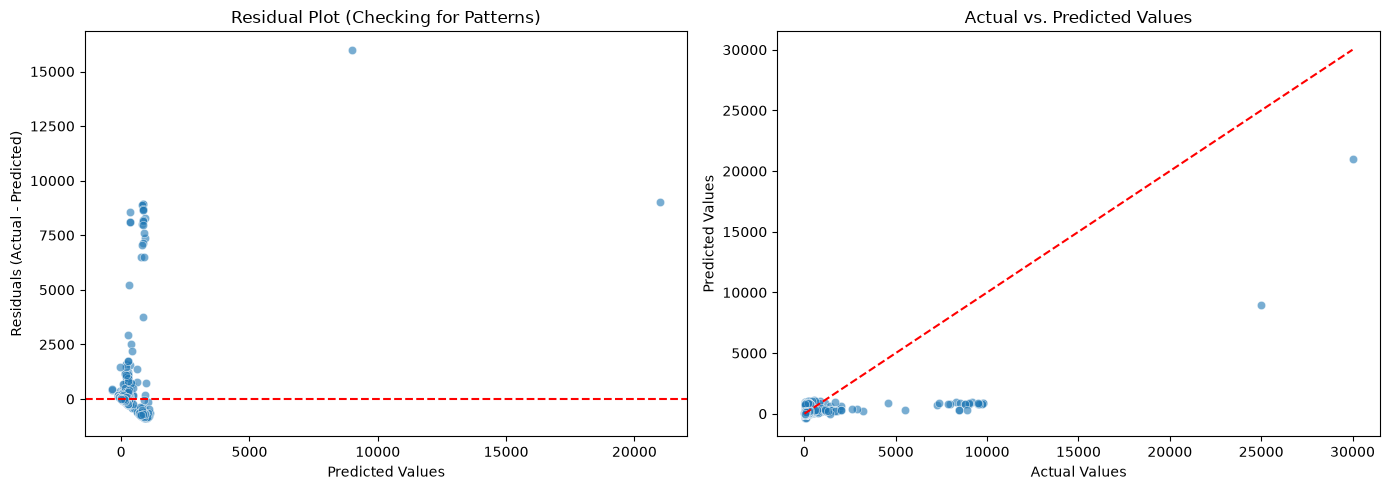

In [154]:
# Calculate residuals (errors)
residuals = y_test - y_pred

# Set up a 1x2 plotting area
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Residuals
sns.scatterplot(x=y_pred, y=residuals, ax=axes[0], alpha=0.6)
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Checking for Patterns)')
axes[0].set_xlabel('Predicted Values')
axes[0].set_ylabel('Residuals (Actual - Predicted)')

# Right Plot: Actual vs Predicted
sns.scatterplot(x=y_test, y=y_pred, ax=axes[1], alpha=0.6)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
axes[1].set_title('Actual vs. Predicted Values')
axes[1].set_xlabel('Actual Values')
axes[1].set_ylabel('Predicted Values')

plt.tight_layout()
plt.show()